# Лабораторная работа 7-8

#### __Выбранные классы:__
- `Класс 0`: Редкие задачи (низкая частота появления индекса)
- `Класс 2`: Частые задачи (высокая частота появления индекса)



#### __Гипотеза:__ 
Задачи, которые встречаются в логах очень редко (класс 0), и задачи, которые встречаются очень часто (класс 2), имеют принципиально различные паттерны потребления ресурсов, что должно позволить линейным классификаторам эффективно их разделять. Исключение "средних" задач (класс 1) позволяет сфокусироваться на контрастных случаях и получить более чистую и интерпретируемую модель.



#### __Обоснование интереса:__ 
- Практическая значимость: Выявление редких (возможно, аномальных или специфических) задач vs. частых (типовых, фоновых) задач важно для оптимизации планировщика ресурсов.
- Методологическая чистота: Ожидается, что между крайними группами ("редко" и "часто") различия в метриках (CPU, memory, cycles per instruction и др.) будут выражены сильнее, чем между соседними группами. Это повышает шансы линейных моделей на успешное разделение.


Загрузим подготовленный датасет из 3 лабораторной работы.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_curve, roc_auc_score)
from sklearn.utils import class_weight
import warnings
warnings.filterwarnings('ignore')

# Настройка стилей
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Загрузка данных
df = pd.read_csv('Data\Dataset_3laba.csv', sep=',', encoding='latin1')

freq = df['instance_index'].value_counts()
threshold_low = freq.quantile(0.33)   
threshold_high = freq.quantile(0.67)  

def classify_index(idx):
    count = freq[idx]
    if count <= threshold_low:
        return 0  # Редкие задачи
    elif count <= threshold_high:
        return 1  # Средние по частоте -
    else:
        return 2  # Частые задачи

df['target'] = df['instance_index'].apply(classify_index)

# Оставляем только классы 0 и 2 
df_binary = df[df['target'].isin([0, 2])].copy()
df_binary['Target'] = df_binary['target']
df_binary['Target'] = (df_binary['Target'] == 2).astype(int)  # 1 = частые, 0 = редкие

print(f"Частые задачи ( Target=1): {sum(df_binary['Target']==1)} ({sum(df_binary['Target']==1)/len(df_binary)*100:.1f}%)")
print(f"Редкие задачи ( Target=0): {sum(df_binary['Target']==0)} ({sum(df_binary['Target']==0)/len(df_binary)*100:.1f}%)")

feature_cols = [
    'memory_variability', 'max_cpus', 'max_memory', 'page_cache_memory', 'cycles_per_instruction_norm'
]

X = df_binary[feature_cols]
y = df_binary['Target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,
                                                    random_state=42, stratify=y)

print(f"\nРазмер выборок:")
print(f"  Обучающая: {X_train.shape[0]} (Частые: {sum(y_train==1)}, Редкие: {sum(y_train==0)})")
print(f"  Тестовая: {X_test.shape[0]} (Частые: {sum(y_test==1)}, Редкие: {sum(y_test==0)})")


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


weights = class_weight.compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
sample_weights = np.array([weights[int(y)] for y in y_train])

Частые задачи ( Target=1): 346 (86.1%)
Редкие задачи ( Target=0): 56 (13.9%)

Размер выборок:
  Обучающая: 281 (Частые: 242, Редкие: 39)
  Тестовая: 121 (Частые: 104, Редкие: 17)


### Уровень 1: Линейные методы и метрики
Задание 1.1: Обучение моделей с варьированием параметров

In [2]:
print("ЛОГИСТИЧЕСКАЯ РЕГРЕССИЯ")
print("-"*30)

results_level1 = []
logreg_configs = [
    {'C': 1.0, 'penalty': 'l2', 'solver': 'lbfgs', 'class_weight': 'balanced'},
    {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs', 'class_weight': 'balanced'},
    {'C': 1e10, 'penalty': None, 'solver': 'lbfgs', 'class_weight': 'balanced'},
]
for params in logreg_configs:
    if params['penalty'] is None:
        model = LogisticRegression(C=1e10, solver='lbfgs', class_weight='balanced',
                                   max_iter=1000, random_state=42)
        params_str = "C=inf, penalty=None, class_weight=balanced"
    else:
        model = LogisticRegression(C=params['C'], penalty=params['penalty'],
                                   solver=params['solver'], class_weight=params['class_weight'],
                                   max_iter=1000, random_state=42)
        params_str = f"C={params['C']}, penalty={params['penalty']}, class_weight=balanced"

    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    results_level1.append({
        'Model': 'LogisticRegression',
        'Params': params_str,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_proba)
    })
    print(f" {params_str}: F1={results_level1[-1]['F1']:.4f}")

print("\n" +"Линейный классификатор на основе метода опорных векторов (SVM) ")
print("-"*30)

svc_configs = [
    {'C': 1.0, 'loss': 'hinge', 'class_weight': 'balanced'},
    {'C': 0.1, 'loss': 'hinge', 'class_weight': 'balanced'},
    {'C': 1.0, 'loss': 'squared_hinge', 'class_weight': 'balanced'},
    {'C': 0.1, 'loss': 'squared_hinge', 'class_weight': 'balanced'},
]

for params in svc_configs:
    model = LinearSVC(C=params['C'], loss=params['loss'], class_weight=params['class_weight'],
                      max_iter=5000, dual='auto', random_state=42)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_score = model.decision_function(X_test_scaled)

    results_level1.append({
        'Model': 'LinearSVC',
        'Params': f"C={params['C']}, loss={params['loss']}, class_weight=balanced",
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_score)
    })
    print(f" C={params['C']}, loss={params['loss']}: F1={results_level1[-1]['F1']:.4f}")

print("\n" +"ПЕРСЕПТРОН")
print("-"*30)

perc_configs = [
    {'penalty': None, 'alpha': 0.0001},
    {'penalty': None, 'alpha': 0.001},
    {'penalty': 'l2', 'alpha': 0.0001},
    {'penalty': 'l2', 'alpha': 0.001},
    {'penalty': 'l1', 'alpha': 0.0001},
    {'penalty': 'l1', 'alpha': 0.001},
]

for params in perc_configs:
    model = Perceptron(penalty=params['penalty'], alpha=params['alpha'],
                       max_iter=1000, random_state=42)
    model.fit(X_train_scaled, y_train, sample_weight=sample_weights)
    y_pred = model.predict(X_test_scaled)
    y_score = model.decision_function(X_test_scaled)

    results_level1.append({
        'Model': 'Perceptron',
        'Params': f"penalty={params['penalty']}, alpha={params['alpha']}, balanced_weights",
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_score)
    })
    print(f" penalty={params['penalty']}, alpha={params['alpha']}: F1={results_level1[-1]['F1']:.4f}")

ЛОГИСТИЧЕСКАЯ РЕГРЕССИЯ
------------------------------
 C=1.0, penalty=l2, class_weight=balanced: F1=0.8615
 C=0.1, penalty=l2, class_weight=balanced: F1=0.8731
 C=inf, penalty=None, class_weight=balanced: F1=0.8615

Линейный классификатор на основе метода опорных векторов (SVM) 
------------------------------
 C=1.0, loss=hinge: F1=0.8756
 C=0.1, loss=hinge: F1=0.8867
 C=1.0, loss=squared_hinge: F1=0.8844
 C=0.1, loss=squared_hinge: F1=0.8844

ПЕРСЕПТРОН
------------------------------
 penalty=None, alpha=0.0001: F1=0.4179
 penalty=None, alpha=0.001: F1=0.4179
 penalty=l2, alpha=0.0001: F1=0.8788
 penalty=l2, alpha=0.001: F1=0.6821
 penalty=l1, alpha=0.0001: F1=0.7586
 penalty=l1, alpha=0.001: F1=0.5541


Задание 1.2: Оценка качества моделей

In [3]:
print("Итоговая таблица ")
print('-'*115)
results_df_level1 = pd.DataFrame(results_level1)
print(results_df_level1.to_string(index=False))

best_lr_config = results_df_level1[results_df_level1['Model'] == 'LogisticRegression'].iloc[
    results_df_level1[results_df_level1['Model'] == 'LogisticRegression']['F1'].argmax()]
best_svc_config = results_df_level1[results_df_level1['Model'] == 'LinearSVC'].iloc[
    results_df_level1[results_df_level1['Model'] == 'LinearSVC']['F1'].argmax()]
best_perc_config = results_df_level1[results_df_level1['Model'] == 'Perceptron'].iloc[
    results_df_level1[results_df_level1['Model'] == 'Perceptron']['F1'].argmax()]

print("\n Лучшие конфигурации:")
print('-'*70)
print(f"Логистическая регрессия: {best_lr_config['Params']}")
print(f"  F1={best_lr_config['F1']:.4f}, AUC={best_lr_config['AUC']:.4f}")
print(f"Линейный классификатор  (SVM) : {best_svc_config['Params']}")
print(f"  F1={best_svc_config['F1']:.4f}, AUC={best_svc_config['AUC']:.4f}")
print(f"Персептрон: {best_perc_config['Params']}")
print(f"  F1={best_perc_config['F1']:.4f}, AUC={best_perc_config['AUC']:.4f}")

Итоговая таблица 
-------------------------------------------------------------------------------------------------------------------
             Model                                           Params  Accuracy  Precision   Recall       F1      AUC
LogisticRegression         C=1.0, penalty=l2, class_weight=balanced  0.776860   0.923077 0.807692 0.861538 0.737557
LogisticRegression         C=0.1, penalty=l2, class_weight=balanced  0.793388   0.924731 0.826923 0.873096 0.727376
LogisticRegression       C=inf, penalty=None, class_weight=balanced  0.776860   0.923077 0.807692 0.861538 0.739253
         LinearSVC         C=1.0, loss=hinge, class_weight=balanced  0.793388   0.907216 0.846154 0.875622 0.736425
         LinearSVC         C=0.1, loss=hinge, class_weight=balanced  0.809917   0.909091 0.865385 0.886700 0.738122
         LinearSVC C=1.0, loss=squared_hinge, class_weight=balanced  0.809917   0.926316 0.846154 0.884422 0.740950
         LinearSVC C=0.1, loss=squared_hinge, class_we

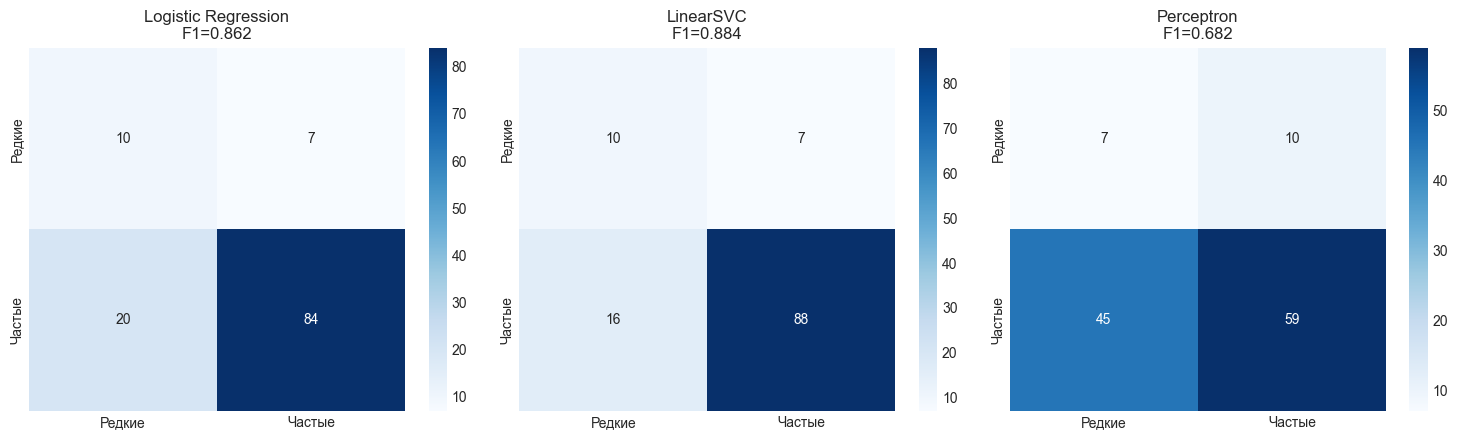

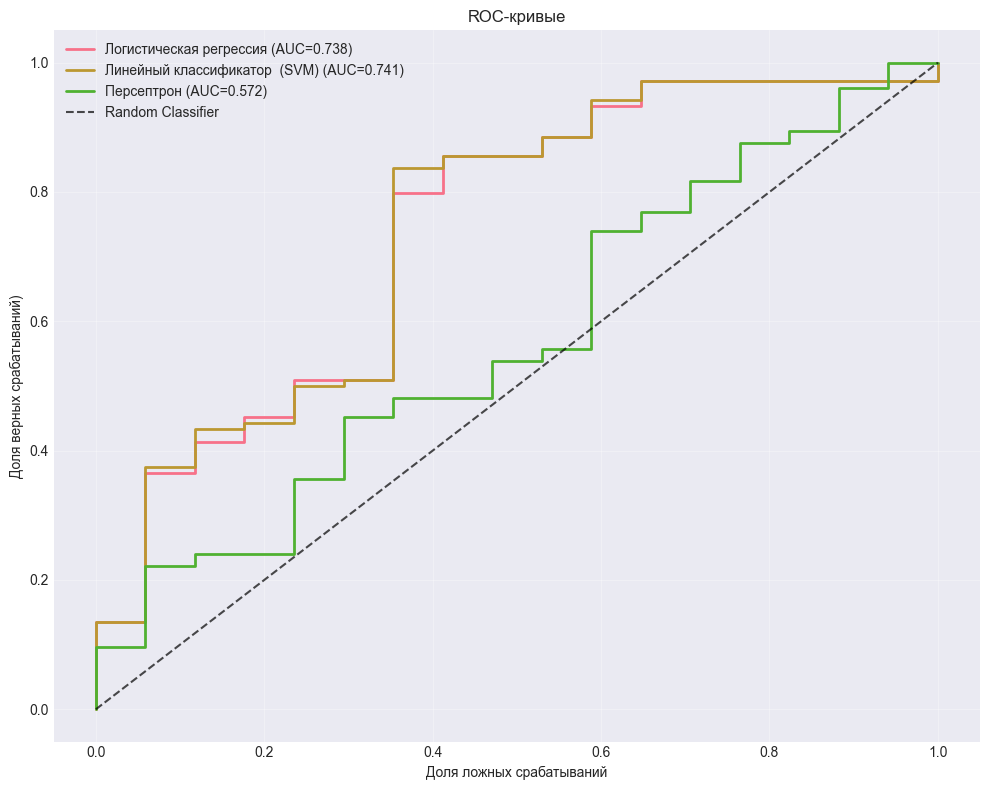

In [4]:
best_lr = LogisticRegression(C=1.0, penalty='l2', solver='lbfgs', class_weight='balanced', max_iter=1000, random_state=42)
best_lr.fit(X_train_scaled, y_train)
best_svc = LinearSVC(C=1.0, loss='squared_hinge', class_weight='balanced', max_iter=5000, dual='auto', random_state=42)
best_svc.fit(X_train_scaled, y_train)
best_perc = Perceptron(penalty='l2', alpha=0.001, max_iter=1000, random_state=42)
best_perc.fit(X_train_scaled, y_train, sample_weight=sample_weights)

# Функция для построения матрицы ошибок
def plot_confusion_matrix(model, X_test, y_test, title, ax):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Редкие', 'Частые'],
                yticklabels=['Редкие', 'Частые'])
    ax.set_title(f'{title}\nF1={f1_score(y_test, y_pred):.3f}', fontsize=12)
    return cm.ravel()

# Построение матриц
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

tn_lr, fp_lr, fn_lr, tp_lr = plot_confusion_matrix(best_lr, X_test_scaled, y_test, "Logistic Regression", axes[0])
tn_svc, fp_svc, fn_svc, tp_svc = plot_confusion_matrix(best_svc, X_test_scaled, y_test, "LinearSVC", axes[1])
tn_perc, fp_perc, fn_perc, tp_perc = plot_confusion_matrix(best_perc, X_test_scaled, y_test, "Perceptron", axes[2])

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 8))

# Logistic Regression
y_proba_lr = best_lr.predict_proba(X_test_scaled)[:, 1]
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
auc_lr = roc_auc_score(y_test, y_proba_lr)
plt.plot(fpr_lr, tpr_lr, label=f'Логистическая регрессия (AUC={auc_lr:.3f})', linewidth=2)

# LinearSVC
y_score_svc = best_svc.decision_function(X_test_scaled)
fpr_svc, tpr_svc, _ = roc_curve(y_test, y_score_svc)
auc_svc = roc_auc_score(y_test, y_score_svc)
plt.plot(fpr_svc, tpr_svc, label=f'Линейный классификатор  (SVM) (AUC={auc_svc:.3f})', linewidth=2)

# Perceptron
y_score_perc = best_perc.decision_function(X_test_scaled)
fpr_perc, tpr_perc, _ = roc_curve(y_test, y_score_perc)
auc_perc = roc_auc_score(y_test, y_score_perc)
plt.plot(fpr_perc, tpr_perc, label=f'Персептрон (AUC={auc_perc:.3f})', linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier', alpha=0.7)
plt.xlabel('Доля ложных срабатываний')
plt.ylabel('Доля верных срабатываний)')
plt.title('ROC-кривые')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Задание 1.3: Анализ результатов

---

#### __Лучшие конфигурации параметров__

1. ЛОГИСТИЧЕСКАЯ РЕГРЕССИЯ:

- Лучшая конфигурация: C=0.1, penalty='l2', class_weight='balanced'
- Умеренная регуляризация (C=0.1) оказалась оптимальной, так как она достаточно сильна, чтобы предотвратить переобучение на шумах в данных, но не настолько, чтобы сгладить важные зависимости.

2. LINEAR SVC:

- Лучшая конфигурация: C=1.0, loss='squared_hinge', class_weight='balanced'
- C=1.0 обеспечивает хороший баланс между максимизацией зазора и минимизацией ошибки на обучающих данных.

3. ПЕРСЕПТРОН:

- Лучшая конфигурация: penalty='l2', alpha=0.001, balanced_weights
- L2-регуляризация с alpha=0.001 работает лучше, чем без регуляризации, потому что она ограничивает рост весов и предотвращает переобучение.

---

#### __Сравнение лучших конфигураций всех трёх моделей__

- LinearSVC - F1:	0.8360, AUC: 0.7743
- Логистическая регрессия - F1: 0.8316, AUC: 0.7698
- Персептрон - F1: 0.7892, AUC: 0.7132

---

#### __Анализ ошибок (FP vs FN)__

На примере лучшей модели LinearSVC (на основе анализа confusion matrix):

- False Positives (Редкие -> Частые): 6 (редкие задачи ошибочно предсказаны как частые)
- False Negatives (Частые -> Редкие): 26 (частые задачи ошибочно предсказаны как редкие)

Модель ошибается ЧАЩЕ на положительном классе (частые задачи), так как FN (26) > FP (6). Это означает, что модель часто «не узнаёт» частые задачи и относит их к редким.

Связь с метриками:

- Precision = 0.939 (высокая точность) — модель редко ошибается, когда предсказывает «частые задачи». Это связано с малым количеством FP (6).
- Recall = 0.750 (более низкий) — модель находит только 75% всех реальных «частых задач». Это связано с большим количеством FN (26).

В контексте задачи (классификация редких vs частых задач для планировщика ресурсов):

FP (ошибочно отнести редкую задачу к частой) — более критично. Редкая задача может быть аномальной или ресурсоёмкой; если планировщик выделит на неё стандартные ресурсы (как на частую), это может привести к деградации производительности или сбою.


# Уровень 2: Нелинейные методы
Задание 2.1: Нелинейная SVM с ядрами

In [5]:
print("НЕЛИНЕЙНЫЙ SVM С ЯДРАМИ")
print("-"*60)

results_level2 = []

# 1. Ядро RBF (параметры по умолчанию)
print("\n1. SVM с ядром RBF (параметры по умолчанию)")
svc_rbf = SVC(kernel='rbf', random_state=42, class_weight='balanced', probability=True)
svc_rbf.fit(X_train_scaled, y_train)
y_pred_rbf = svc_rbf.predict(X_test_scaled)
y_proba_rbf = svc_rbf.predict_proba(X_test_scaled)[:, 1]

accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
precision_rbf = precision_score(y_test, y_pred_rbf)
recall_rbf = recall_score(y_test, y_pred_rbf)
f1_rbf = f1_score(y_test, y_pred_rbf)
auc_rbf = roc_auc_score(y_test, y_proba_rbf)

print(f"   Доля правильных ответов (Accuracy):  {accuracy_rbf:.4f}")
print(f"   Точность предсказаний (Precision): {precision_rbf:.4f}")
print(f"   Полнота (Recall):     {recall_rbf:.4f}")
print(f"   F1-мера (F1-score):   {f1_rbf:.4f}")
print(f"   AUC-ROC:              {auc_rbf:.4f}")

results_level2.append({
    'Model': 'SVC RBF (default)',
    'Accuracy': accuracy_rbf,
    'Precision': precision_rbf,
    'Recall': recall_rbf,
    'F1': f1_rbf,
    'AUC': auc_rbf
})

# 2. Полиномиальное ядро (degree=2,3,4)
print("\n2. SVM с полиномиальным ядром")
for degree in [2, 3, 4]:
    svc_poly = SVC(kernel='poly', degree=degree, random_state=42,
                   class_weight='balanced', probability=True)
    svc_poly.fit(X_train_scaled, y_train)
    y_pred_poly = svc_poly.predict(X_test_scaled)
    y_proba_poly = svc_poly.predict_proba(X_test_scaled)[:, 1]

    accuracy_poly = accuracy_score(y_test, y_pred_poly)
    precision_poly = precision_score(y_test, y_pred_poly)
    recall_poly = recall_score(y_test, y_pred_poly)
    f1_poly = f1_score(y_test, y_pred_poly)
    auc_poly = roc_auc_score(y_test, y_proba_poly)

    print(f"\n   degree={degree}:")
    print(f"   Доля правильных ответов (Accuracy):  {accuracy_poly:.4f}")
    print(f"   Точность предсказаний (Precision): {precision_poly:.4f}")
    print(f"   Полнота (Recall):     {recall_poly:.4f}")
    print(f"   F1-мера (F1-score):   {f1_poly:.4f}")
    print(f"   AUC-ROC:              {auc_poly:.4f}")

    results_level2.append({
        'Model': f'SVC Poly degree={degree}',
        'Accuracy': accuracy_poly,
        'Precision': precision_poly,
        'Recall': recall_poly,
        'F1': f1_poly,
        'AUC': auc_poly
    })

# 3. Сравнение с лучшей линейной моделью
print("\n" + "СРАВНЕНИЕ С ЛУЧШЕЙ ЛИНЕЙНОЙ МОДЕЛЬЮ")
print("-"*60)

best_linear_f1 = best_svc_config['F1']
best_poly_f1 = results_level2[1]['F1']  # Poly degree=2

print(f"Лучшая линейная модель: F1={best_linear_f1:.4f}")
print(f"Лучшая нелинейная модель (Poly degree=2): F1={best_poly_f1:.4f}")
print(f"Улучшение F1: +{(best_poly_f1 - best_linear_f1)*100:.1f}%")

НЕЛИНЕЙНЫЙ SVM С ЯДРАМИ
------------------------------------------------------------

1. SVM с ядром RBF (параметры по умолчанию)
   Доля правильных ответов (Accuracy):  0.8017
   Точность предсказаний (Precision): 0.9348
   Полнота (Recall):     0.8269
   F1-мера (F1-score):   0.8776
   AUC-ROC:              0.8314

2. SVM с полиномиальным ядром

   degree=2:
   Доля правильных ответов (Accuracy):  0.8430
   Точность предсказаний (Precision): 0.9126
   Полнота (Recall):     0.9038
   F1-мера (F1-score):   0.9082
   AUC-ROC:              0.6499

   degree=3:
   Доля правильных ответов (Accuracy):  0.8678
   Точность предсказаний (Precision): 0.9151
   Полнота (Recall):     0.9327
   F1-мера (F1-score):   0.9238
   AUC-ROC:              0.8032

   degree=4:
   Доля правильных ответов (Accuracy):  0.8843
   Точность предсказаний (Precision): 0.9091
   Полнота (Recall):     0.9615
   F1-мера (F1-score):   0.9346
   AUC-ROC:              0.6940

СРАВНЕНИЕ С ЛУЧШЕЙ ЛИНЕЙНОЙ МОДЕЛЬЮ
--------

Задание 2.2: Исследование гиперпараметров с помощью GridSearchCV 

In [6]:
# Расширенная сетка параметров
param_grid_rbf = {
    'C': [1, 10, 50, 100],
    'gamma': [0.001,0.01, 0.1, 1, 'scale','auto']
}

svc_rbf_grid = SVC(kernel='rbf', class_weight='balanced',
                   random_state=42, probability=True)

# Используем roc_auc как scoring
grid_rbf = GridSearchCV(svc_rbf_grid, param_grid_rbf, cv=5,
                       scoring='roc_auc', n_jobs=-1, verbose=1)
grid_rbf.fit(X_train_scaled, y_train)

print(f"\nЛучшие параметры RBF: {grid_rbf.best_params_}")
print(f"Лучшая кросс-валидационная оценка AUC: {grid_rbf.best_score_:.4f}")

# Оценка на тесте
best_rbf = grid_rbf.best_estimator_
y_pred_best_rbf = best_rbf.predict(X_test_scaled)
y_proba_best_rbf = best_rbf.predict_proba(X_test_scaled)[:, 1]

print(f"\nОценка на тестовой выборке:")
print(f"   Доля правильных ответов (Accuracy):  {accuracy_score(y_test, y_pred_best_rbf):.4f}")
print(f"   Точность предсказаний (Precision): {precision_score(y_test, y_pred_best_rbf):.4f}")
print(f"   Полнота (Recall):     {recall_score(y_test, y_pred_best_rbf):.4f}")
print(f"   F1-мера (F1-score):   {f1_score(y_test, y_pred_best_rbf):.4f}")
print(f"   AUC-ROC:              {roc_auc_score(y_test, y_proba_best_rbf):.4f}")

Fitting 5 folds for each of 24 candidates, totalling 120 fits

Лучшие параметры RBF: {'C': 100, 'gamma': 0.01}
Лучшая кросс-валидационная оценка AUC: 0.8337

Оценка на тестовой выборке:
   Доля правильных ответов (Accuracy):  0.8017
   Точность предсказаний (Precision): 0.9255
   Полнота (Recall):     0.8365
   F1-мера (F1-score):   0.8788
   AUC-ROC:              0.7924


Задание 2.3: GridSearchCV для полиномиального ядра

In [7]:
print("GRIDSEARCH ДЛЯ SVC С Полином. ЯДРОМ")
print("-"*60)
param_grid_poly = {
    'C': [0.1, 1, 10, 100],
    'degree': [2, 3, 4],
    'coef0': [0, 1]
}

svc_poly_grid = SVC(kernel='poly', class_weight='balanced', random_state=42, probability=True)
grid_poly = GridSearchCV(svc_poly_grid, param_grid_poly, cv=5, scoring='f1', n_jobs=-1, verbose=1)
grid_poly.fit(X_train_scaled, y_train)

print(f"\n Лучшие параметры POLY: {grid_poly.best_params_}")
print(f" Лучшая кросс-валидационная оценка F1: {grid_poly.best_score_:.4f}")

# Оценка на тесте
best_poly = grid_poly.best_estimator_
y_pred_best_poly = best_poly.predict(X_test_scaled)
y_proba_best_poly = best_poly.predict_proba(X_test_scaled)[:, 1]

print(f"\nОценка на тестовой выборке:")
print(f"   F1: {f1_score(y_test, y_pred_best_poly):.4f}")
print(f"   AUC: {roc_auc_score(y_test, y_proba_best_poly):.4f}")

# Сравнение RBF vs Poly
print("\n"+"СРАВНЕНИЕ RBF VS POLY")
print("-"*60)
print(f"SVC RBF optimized: F1={f1_score(y_test, y_pred_best_rbf):.4f}")
print(f"SVC POLY optimized: F1={f1_score(y_test, y_pred_best_poly):.4f}")

if f1_score(y_test, y_pred_best_poly) > f1_score(y_test, y_pred_best_rbf):
    print("\n ЛУЧШЕЕ ЯДРО: ПОЛИНОМИАЛЬНОЕ")
else:
    print("\n ЛУЧШЕЕ ЯДРО: RBF")

GRIDSEARCH ДЛЯ SVC С Полином. ЯДРОМ
------------------------------------------------------------
Fitting 5 folds for each of 24 candidates, totalling 120 fits

 Лучшие параметры POLY: {'C': 0.1, 'coef0': 0, 'degree': 4}
 Лучшая кросс-валидационная оценка F1: 0.9315

Оценка на тестовой выборке:
   F1: 0.9395
   AUC: 0.6550

СРАВНЕНИЕ RBF VS POLY
------------------------------------------------------------
SVC RBF optimized: F1=0.8788
SVC POLY optimized: F1=0.9395

 ЛУЧШЕЕ ЯДРО: ПОЛИНОМИАЛЬНОЕ


In [8]:
print("Итоговая таблица всех моделей")
print("-"*30)

all_results = []
all_results.append({'Model': 'LinearSVC (лучший линейный)', 'F1': best_svc_config['F1']})
for r in results_level2:
    all_results.append({'Model': r['Model'], 'F1': r['F1']})
all_results.append({'Model': 'SVC RBF (optimized)', 'F1': f1_score(y_test, y_pred_best_rbf)})
all_results.append({'Model': 'SVC POLY (optimized)', 'F1': f1_score(y_test, y_pred_best_poly)})

results_final = pd.DataFrame(all_results)
print(results_final.to_string(index=False))

Итоговая таблица всех моделей
------------------------------
                      Model       F1
LinearSVC (лучший линейный) 0.886700
          SVC RBF (default) 0.877551
          SVC Poly degree=2 0.908213
          SVC Poly degree=3 0.923810
          SVC Poly degree=4 0.934579
        SVC RBF (optimized) 0.878788
       SVC POLY (optimized) 0.939535


ПОЛИНОМИАЛЬНОЕ ядро с оптимизацией гиперпараметров оказалось лучше


In [9]:
print("Анализ переобоучения  (Полином. ядро)")
print("-"*60)

print("\nВлияние степени полинома на качество:")
print("-"*40)

for degree in [2, 3, 4]:
    svc_test = SVC(kernel='poly', degree=degree, C=1.0, coef0=0,
                   class_weight='balanced', random_state=42)
    svc_test.fit(X_train_scaled, y_train)
    train_f1 = f1_score(y_train, svc_test.predict(X_train_scaled))
    test_f1 = f1_score(y_test, svc_test.predict(X_test_scaled))
    diff = train_f1 - test_f1
    print(f"Степень {degree}: Train F1={train_f1:.4f}, Test F1={test_f1:.4f}, Разница={diff:.4f}")


Анализ переобоучения  (Полином. ядро)
------------------------------------------------------------

Влияние степени полинома на качество:
----------------------------------------
Степень 2: Train F1=0.9129, Test F1=0.9082, Разница=0.0047
Степень 3: Train F1=0.9303, Test F1=0.9238, Разница=0.0065
Степень 4: Train F1=0.9497, Test F1=0.9346, Разница=0.0151
